# Grad-CAM: wrong predictions

Original bandwidth CNN, ViT-Tiny, DINOv2 and VMamba. Audit the original 45 validation images, then explain **every mistake** in either direction. No training.

Each example: **original / wrong predicted-class Grad-CAM / true-class Grad-CAM**. Current checkpoints have only true Low → predicted High mistakes; no reverse errors are invented.

## 1. Settings

Use your existing PyTorch environment. Set `PACKAGE_ROOT` to the same complete folder used for the earlier LIME analysis. All implementation code is visible below.

In [1]:
from pathlib import Path
import os
import torch

# Original bandwidth package previously used for LIME (not the RDN package).
PACKAGE_ROOT = Path(os.environ.get('BANDWIDTH_XAI_ROOT',
    '/Users/olzh/Documents/Paper replication/original_bandwidth_explainability_lab')).expanduser()

# Edit PACKAGE_ROOT above when running on the lab computer.
MODELS = ['cnn', 'vit_tiny', 'dinov2', 'vmamba']
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
# Explicit CPU reference mode for VMamba; slower than its CUDA extension.
ALLOW_VMAMBA_CPU_REFERENCE = True
CPU_THREADS = 4

# Find this notebook's folder whether launched from its directory or project root.
HERE = Path.cwd()
CANDIDATES = [HERE, HERE / 'gradcam_xai', HERE.parent / 'gradcam_xai']
NOTEBOOK_DIR = next((p for p in CANDIDATES if (p / 'EXPECTED_INPUTS.json').is_file()), None)
if NOTEBOOK_DIR is None:
    raise FileNotFoundError('Keep EXPECTED_INPUTS.json beside this notebook; launch Jupyter in the project folder.')
OUTPUT_ROOT = NOTEBOOK_DIR / 'results'
print('Package:', PACKAGE_ROOT)
print('Device:', DEVICE, '| Models:', MODELS)


Package: /Users/olzh/Documents/Paper replication/original_bandwidth_explainability_lab
Device: cpu | Models: ['cnn', 'vit_tiny', 'dinov2', 'vmamba']


## 2. Grad-CAM implementation

We spatially average the target-logit gradients to weight each feature channel, sum the weighted activations, and retain positive evidence with ReLU. ViT maps remove the CLS token before reshaping patches. Each target is normalized independently.

[Grad-CAM paper](https://openaccess.thecvf.com/content_ICCV_2017/html/Selvaraju_Grad-CAM_Visual_Explanations_ICCV_2017_paper.html) · [Transformer layer guidance](https://github.com/jacobgil/pytorch-grad-cam/blob/master/tutorials/vision_transformers.md)

In [2]:
"""Grad-CAM error analysis for the original four bandwidth classifiers.

No training, weight downloads, or checkpoint selection takes place here.
"""
import csv
import gc
import hashlib
import importlib.metadata
import json
import sys
from pathlib import Path

import numpy as np
from PIL import Image
import torch
from torch.nn import functional as F

NAMES = {'cnn': 'CNN', 'vit_tiny': 'ViT-Tiny', 'dinov2': 'DINOv2', 'vmamba': 'VMamba-Tiny'}
CLASSES = {0: 'Low', 1: 'High'}


def sha256(path):
    value = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            value.update(block)
    return value.hexdigest()


def state_hash(model):
    value = hashlib.sha256()
    for name, tensor in model.state_dict().items():
        value.update(name.encode())
        value.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return value.hexdigest()


def write_json(path, value):
    Path(path).write_text(json.dumps(value, indent=2, allow_nan=False) + '\n')


def write_csv(path, rows):
    if rows:
        with Path(path).open('w', newline='') as stream:
            writer = csv.DictWriter(stream, fieldnames=list(rows[0]))
            writer.writeheader()
            writer.writerows(rows)


def to_spatial(tensor, layout, grid=None):
    """Apply exactly the same spatial reshape to activations and gradients."""
    if layout == 'bchw':
        if tensor.ndim != 4:
            raise ValueError('Expected BCHW activation')
        return tensor
    if layout == 'bhwc':
        if tensor.ndim != 4:
            raise ValueError('Expected BHWC activation')
        return tensor.permute(0, 3, 1, 2)
    if layout == 'tokens':
        if tensor.ndim != 3 or grid is None:
            raise ValueError('Token Grad-CAM needs an explicit patch grid')
        height, width = grid
        if tensor.shape[1] != height * width + 1:
            raise ValueError('Expected one CLS token followed by all spatial patches')
        return tensor[:, 1:, :].reshape(tensor.shape[0], height, width, tensor.shape[-1]).permute(0, 3, 1, 2)
    raise ValueError(layout)


def gradcam(model, layer, image, layout='bchw', grid=None):
    """Two class-logit Grad-CAM maps, with unchanged model weights.

    The target activation is made a gradient leaf. This preserves its value
    and the complete downstream computation, and obtains d(logit)/d(activation)
    without retaining an unnecessary upstream graph for frozen backbones.
    """
    if torch.is_inference_mode_enabled():
        raise RuntimeError('Run Grad-CAM outside torch.inference_mode().')
    if image.shape[0] != 1 or model.training:
        raise ValueError('Use one image and model.eval()')
    captured = []

    def capture(_module, _inputs, output):
        if not isinstance(output, torch.Tensor):
            raise TypeError('The selected layer must return one tensor')
        activation = output.detach().requires_grad_(True)
        captured.append(activation)
        return activation

    with torch.no_grad():
        baseline = model(image).detach()
    handle = layer.register_forward_hook(capture)
    try:
        with torch.enable_grad():
            logits = model(image)
            if len(captured) != 1 or logits.shape != (1, 2):
                raise RuntimeError('Expected one target-layer call and two class logits')
            if not torch.allclose(logits, baseline, atol=2e-5, rtol=2e-5):
                raise RuntimeError('The attribution hook changed model logits')
            activation = captured[0]
            spatial = to_spatial(activation, layout, grid)
            maps = {}
            for target in (0, 1):
                gradient, = torch.autograd.grad(logits[0, target], activation, retain_graph=target == 0)
                gradient = to_spatial(gradient, layout, grid)
                if not torch.isfinite(gradient).all() or not torch.isfinite(spatial).all():
                    raise RuntimeError('Non-finite activation or gradient')
                weights = gradient.mean(dim=(2, 3), keepdim=True)
                signed = (weights * spatial).sum(dim=1)[0]
                positive = signed.clamp_min(0)
                peak = float(positive.max().detach())
                empty = peak <= 1e-12
                normalized = torch.zeros_like(positive) if empty else positive / peak
                maps[target] = {
                    'signed_native': signed.detach().cpu().numpy(),
                    'positive_native': positive.detach().cpu().numpy(),
                    'normalized_native': normalized.detach().cpu().numpy(),
                    'positive_peak': peak, 'empty_positive_map': empty,
                    'gradient_max_abs': float(gradient.abs().max().detach()),
                }
        return {'logits': logits.detach().cpu().numpy()[0],
                'probabilities': logits.detach().softmax(1).cpu().numpy()[0],
                'hook_max_logit_difference': float((logits.detach() - baseline).abs().max()),
                'maps': maps}
    finally:
        handle.remove()


def target_layer(model, name):
    if name == 'cnn':
        return model.features[6], 'features.6 (last convolution)', 'bchw', None
    if name in ('vit_tiny', 'dinov2'):
        grid = (14, 14) if name == 'vit_tiny' else (16, 16)
        return model.blocks[-1].norm1, 'blocks.11.norm1 (before final attention)', 'tokens', grid
    if name == 'vmamba':
        backbone = model.backbone
        layout = 'bchw' if backbone.channel_first else 'bhwc'
        return backbone.classifier.norm, 'backbone.classifier.norm (before spatial pooling)', layout, None
    raise ValueError(name)


def resize_map(native, shape):
    tensor = torch.from_numpy(native.astype(np.float32))[None, None]
    return F.interpolate(tensor, size=shape, mode='bilinear', align_corners=False)[0, 0].numpy()


def save_case(directory, rgb, result, record):
    from matplotlib import colormaps, pyplot as plt
    directory.mkdir(parents=True, exist_ok=True)
    Image.fromarray(rgb).save(directory / 'original.png')
    predicted, truth = record['predicted_label'], record['true_label']
    arrays = {}
    for label in (0, 1):
        item = result['maps'][label]
        heatmap = resize_map(item['normalized_native'], rgb.shape[:2])
        color = colormaps['inferno'](heatmap)[..., :3]
        # Keep zero-attribution pixels unchanged; color strength follows CAM.
        alpha = 0.65 * heatmap[..., None]
        overlay = (rgb / 255.0) * (1 - alpha) + color * alpha
        Image.fromarray(np.rint(np.clip(overlay, 0, 1) * 255).astype(np.uint8)).save(directory / f'{CLASSES[label].lower()}_overlay.png')
        for key in ('signed_native', 'positive_native', 'normalized_native'):
            arrays[f'{CLASSES[label].lower()}_{key}'] = item[key]
        arrays[f'{CLASSES[label].lower()}_upsampled'] = heatmap
        record[f'{CLASSES[label].lower()}_empty_positive_map'] = item['empty_positive_map']
        record[f'{CLASSES[label].lower()}_positive_peak'] = item['positive_peak']
        record[f'{CLASSES[label].lower()}_gradient_max_abs'] = item['gradient_max_abs']
    np.savez_compressed(directory / 'maps.npz', **arrays)
    fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))
    for axis, file, title in zip(axes,
        ['original.png', f'{CLASSES[predicted].lower()}_overlay.png', f'{CLASSES[truth].lower()}_overlay.png'],
        [f"Original: true {CLASSES[truth]}", f"Predicted {CLASSES[predicted]} logit", f"True {CLASSES[truth]} logit"]):
        axis.imshow(Image.open(directory / file))
        if file != 'original.png':
            target = predicted if file.startswith(CLASSES[predicted].lower()) else truth
            if result['maps'][target]['empty_positive_map']:
                title += '\nNo positive CAM after ReLU'
        axis.set_title(title)
        axis.axis('off')
    fig.suptitle(f"{NAMES[record['model']]} | {Path(record['file']).stem.split('_')[0]} | "
                 f"wrong prediction: {CLASSES[predicted]} ({record['prediction_confidence']:.2%})")
    fig.text(.5, .015, 'Bright color: stronger positive Grad-CAM; each target is normalized separately.', ha='center', fontsize=10)
    fig.tight_layout(rect=(0, .04, 1, .94))
    fig.savefig(directory / 'comparison.png', dpi=150)
    plt.close(fig)
    write_json(directory / 'metadata.json', record)


def select_errors(audit):
    groups = {'true_low_predicted_high': [], 'true_high_predicted_low': []}
    for row in audit:
        truth, prediction = int(row['true_label']), int(row['predicted_label'])
        if truth != prediction:
            groups['true_low_predicted_high' if truth == 0 else 'true_high_predicted_low'].append(row)
    for group in groups.values():
        group.sort(key=lambda row: row['file'])
    return groups


def run_analysis(package_root, output_root, models=('cnn', 'vit_tiny', 'dinov2', 'vmamba'),
                 device=None, allow_vmamba_cpu_reference=False, expected_inputs=None, threads=4):
    """Audit all 45 images, then explain ALL errors in either direction."""
    package_root, output_root = Path(package_root).expanduser().resolve(), Path(output_root).expanduser().resolve()
    if not models or len(set(models)) != len(models) or any(m not in NAMES for m in models):
        raise ValueError('Select unique names from cnn, vit_tiny, dinov2, vmamba')
    if not (package_root / 'xai_code/models.py').is_file():
        raise FileNotFoundError('Set PACKAGE_ROOT to the original bandwidth XAI folder containing data/, checkpoints/, reference/, xai_code/.')
    if expected_inputs is None:
        raise ValueError('Pass the distributed EXPECTED_INPUTS.json to pin the original inputs')
    expected = json.loads(Path(expected_inputs).read_text())
    for relative, digest in expected.items():
        if sha256(package_root / relative) != digest:
            raise ValueError(f'Original package identity mismatch: {relative}')
    sys.path.insert(0, str(package_root))
    import xai_code
    if Path(xai_code.__file__).resolve().parent != package_root / 'xai_code':
        raise RuntimeError('A different xai_code package is already imported; restart the kernel')
    from xai_code.models import build_model, Predictor
    from xai_code.runtime import samples, read_rgb
    device = torch.device(device or ('cuda' if torch.cuda.is_available() else 'cpu'))
    if device.type not in ('cpu', 'cuda'):
        raise ValueError('Use CPU or CUDA for reproducibility with the original checkpoints')
    if 'vmamba' in models and device.type != 'cuda' and not allow_vmamba_cpu_reference:
        raise RuntimeError('VMamba needs CUDA, or explicitly enable ALLOW_VMAMBA_CPU_REFERENCE for the slower verified CPU scan.')
    torch.set_num_threads(threads)
    torch.manual_seed(42)
    np.random.seed(42)
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False
    torch.backends.cudnn.benchmark = False
    rows = samples(package_root)
    images = {row['file']: read_rgb(package_root, row) for row in rows}
    for row in rows:
        if sha256(package_root / row['relative_path']) != row['sha256']:
            raise ValueError(f"Image hash mismatch: {row['file']}")
    versions = {name: importlib.metadata.version(name) for name in ('torch', 'torchvision', 'timm', 'numpy', 'Pillow', 'matplotlib')}
    identity = {'method': 'Grad-CAM: ReLU(sum_k(mean_spatial(d logit_c / d A_k) * A_k))',
                'models': list(models), 'device': str(device), 'versions': versions,
                'expected_inputs_sha256': sha256(expected_inputs),
                'workflow_sha256': sha256(Path(__file__)) if '__file__' in globals() and Path(__file__).is_file() else None,
                'dataset': 'original bandwidth; 176 training / 45 validation / 0 independent test',
                'selection': 'all current misclassifications; both directions; no confidence filtering',
                'allow_vmamba_cpu_reference': allow_vmamba_cpu_reference,
                'class_names': CLASSES, 'parameters_updated': False, 'threads': threads}
    run_id = hashlib.sha256(json.dumps(identity, sort_keys=True).encode()).hexdigest()[:16]
    output = output_root / run_id
    output.mkdir(parents=True, exist_ok=True)
    write_json(output / 'configuration.json', identity)
    summaries, statuses = [], []
    for name in models:
        print(f'Loading and auditing {NAMES[name]} on {device}...', flush=True)
        model = build_model(package_root, name, device, require_fast_vmamba=device.type == 'cuda')
        initial_state = state_hash(model)
        predictor = Predictor(model, name, device, batch_size=1)
        archived = {r['file']: r for r in csv.DictReader((package_root / 'reference' / name / 'best_accuracy_predictions.csv').open())}
        if set(archived) != set(images):
            raise ValueError('Archived sample identities differ')
        audit = []
        for row in rows:
            probs = predictor([images[row['file']]])[0]
            old = archived[row['file']]
            if row['label'] != int(old['true_label']):
                raise ValueError('True labels differ from original predictions')
            audit.append({'file': row['file'], 'true_label': row['label'],
                'predicted_label': int(probs.argmax()), 'probability_low': float(probs[0]),
                'probability_high': float(probs[1]), 'archived_prediction': int(old['predicted_label']),
                'max_probability_difference': float(np.max(np.abs(probs - np.array([float(old['probability_low']), float(old['probability_high'])]))))})
        model_output = output / name
        model_output.mkdir(exist_ok=True)
        write_csv(model_output / 'prediction_audit.csv', audit)
        changed = [r['file'] for r in audit if r['predicted_label'] != r['archived_prediction']]
        drift = max(r['max_probability_difference'] for r in audit)
        if changed or drift > 5e-4:
            raise RuntimeError(f'{name}: prediction/probability drift exceeds tolerance. Inspect prediction_audit.csv before explaining; changed={changed}, max drift={drift}')
        groups = select_errors(audit)
        layer, layer_name, layout, grid = target_layer(model, name)
        status = {'model': name, 'audited_images': len(audit), 'correct': sum(r['true_label'] == r['predicted_label'] for r in audit),
                  'false_high_count': len(groups['true_low_predicted_high']), 'false_low_count': len(groups['true_high_predicted_low']),
                  'maximum_probability_drift': drift, 'target_layer': layer_name, 'layout': layout,
                  'vmamba_backend': ('CUDA selective_scan' if device.type == 'cuda' else 'PyTorch CPU reference') if name == 'vmamba' else None}
        print(f"{NAMES[name]}: {status['false_high_count']} false High, {status['false_low_count']} false Low", flush=True)
        for direction, errors in groups.items():
            for row in errors:
                image = predictor.tensor(images[row['file']]).unsqueeze(0).to(device)
                result = gradcam(model, layer, image, layout, grid)
                if int(result['probabilities'].argmax()) != row['predicted_label']:
                    raise RuntimeError('Prediction changed during attribution')
                record = dict(row, model=name, direction=direction, target_layer=layer_name,
                    prediction_confidence=float(result['probabilities'][row['predicted_label']]),
                    low_logit=float(result['logits'][0]), high_logit=float(result['logits'][1]),
                    hook_max_logit_difference=result['hook_max_logit_difference'],
                    checkpoint_sha256=sha256(package_root / f'checkpoints/{name}_best_accuracy.pth'),
                    map_normalization='each class independently, positive maximum; magnitudes not comparable between classes',
                    output_directory=str(model_output / Path(row['file']).stem))
                save_case(Path(record['output_directory']), images[row['file']], result, record)
                summaries.append(record)
                print(f"  Saved {Path(row['file']).stem.split('_')[0]}: true {CLASSES[row['true_label']]} -> predicted {CLASSES[row['predicted_label']]} ({record['prediction_confidence']:.2%})", flush=True)
        if state_hash(model) != initial_state or any(p.grad is not None for p in model.parameters()):
            raise RuntimeError('Unexpected model state or parameter-gradient mutation')
        status['weights_unchanged'] = True
        statuses.append(status)
        write_json(model_output / 'status.json', status)
        write_json(output / 'summary.json', summaries)
        write_csv(output / 'summary.csv', summaries)
        write_json(output / 'model_status.json', statuses)
        del predictor, model
        gc.collect()
        if device.type == 'cuda':
            torch.cuda.empty_cache()
    print(f'Finished: {len(summaries)} error explanations. Outputs: {output}', flush=True)
    return output, summaries, statuses


## 3. Audit predictions and explain errors

This cell runs inference and attribution only. It verifies input/checkpoint identities, stops on prediction drift, handles missing error directions, and verifies that weights remain unchanged.

In [3]:
OUTPUT_DIR, SUMMARY, MODEL_STATUS = run_analysis(
    PACKAGE_ROOT, OUTPUT_ROOT, models=MODELS, device=DEVICE,
    allow_vmamba_cpu_reference=ALLOW_VMAMBA_CPU_REFERENCE,
    expected_inputs=NOTEBOOK_DIR / 'EXPECTED_INPUTS.json', threads=CPU_THREADS)


Loading and auditing CNN on cpu...


CNN: 1 false High, 0 false Low


  Saved M93: true Low -> predicted High (96.35%)


Loading and auditing ViT-Tiny on cpu...


ViT-Tiny: 2 false High, 0 false Low


...

Loading and auditing VMamba-Tiny on cpu...


/Users/olzh/Documents/Paper replication/original_bandwidth_explainability_lab/xai_code/vmamba_official.py:30: UserWarning: Triton not installed, fall back to pytorch implements.
  warnings.warn("Triton not installed, fall back to pytorch implements.")
/Users/olzh/Documents/Paper replication/original_bandwidth_explainability_lab/xai_code/vmamba_official.py:854: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  def forward(ctx, u, delta, A, B, C, D=None, delta_bias=None, delta_softplus=False, oflex=True, backend=None):
/Users/olzh/Documents/Paper replication/original_bandwidth_explainability_lab/xai_code/vmamba_official.py:869: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  def backward(ctx, dout, *args):
/Users/olzh/Documents/Paper replication/.venv/lib/python3.9/site-packages/timm/models/layers/__init__.

VMamba-Tiny: 1 false High, 0 false Low


  Saved M93: true Low -> predicted High (93.25%)


Finished: 6 error explanations. Outputs: /Users/olzh/Documents/16-19.10.26-training-finetuned-models/gradcam_xai/results/53bd12555dbda8d0


## 4. Inspect each wrong prediction

**CNN:** 1 true Low → predicted High; 0 true High → predicted Low. All 45 validation predictions audited.

No true High → predicted Low case exists for this saved checkpoint.

**ViT-Tiny:** 2 true Low → predicted High; 0 true High → predicted Low. All 45 validation predictions audited.

No true High → predicted Low case exists for this saved checkpoint.

**DINOv2:** 2 true Low → predicted High; 0 true High → predicted Low. All 45 validation predictions audited.

No true High → predicted Low case exists for this saved checkpoint.

**VMamba-Tiny:** 1 true Low → predicted High; 0 true High → predicted Low. All 45 validation predictions audited.

No true High → predicted Low case exists for this saved checkpoint.

### CNN — M93
True **Low**, predicted **High** with probability **96.35%**.

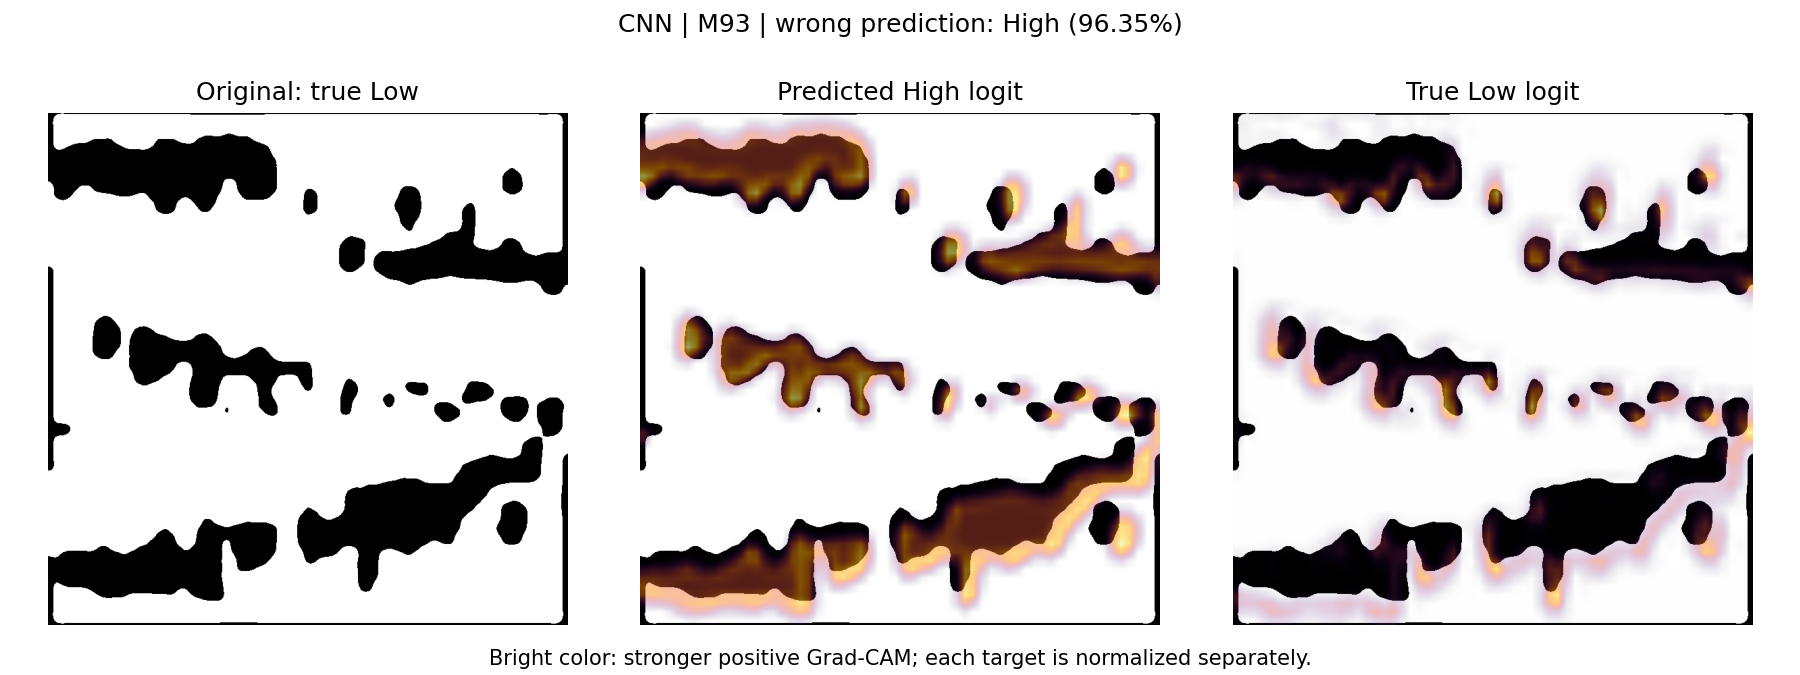

### ViT-Tiny — M323
True **Low**, predicted **High** with probability **57.55%**.

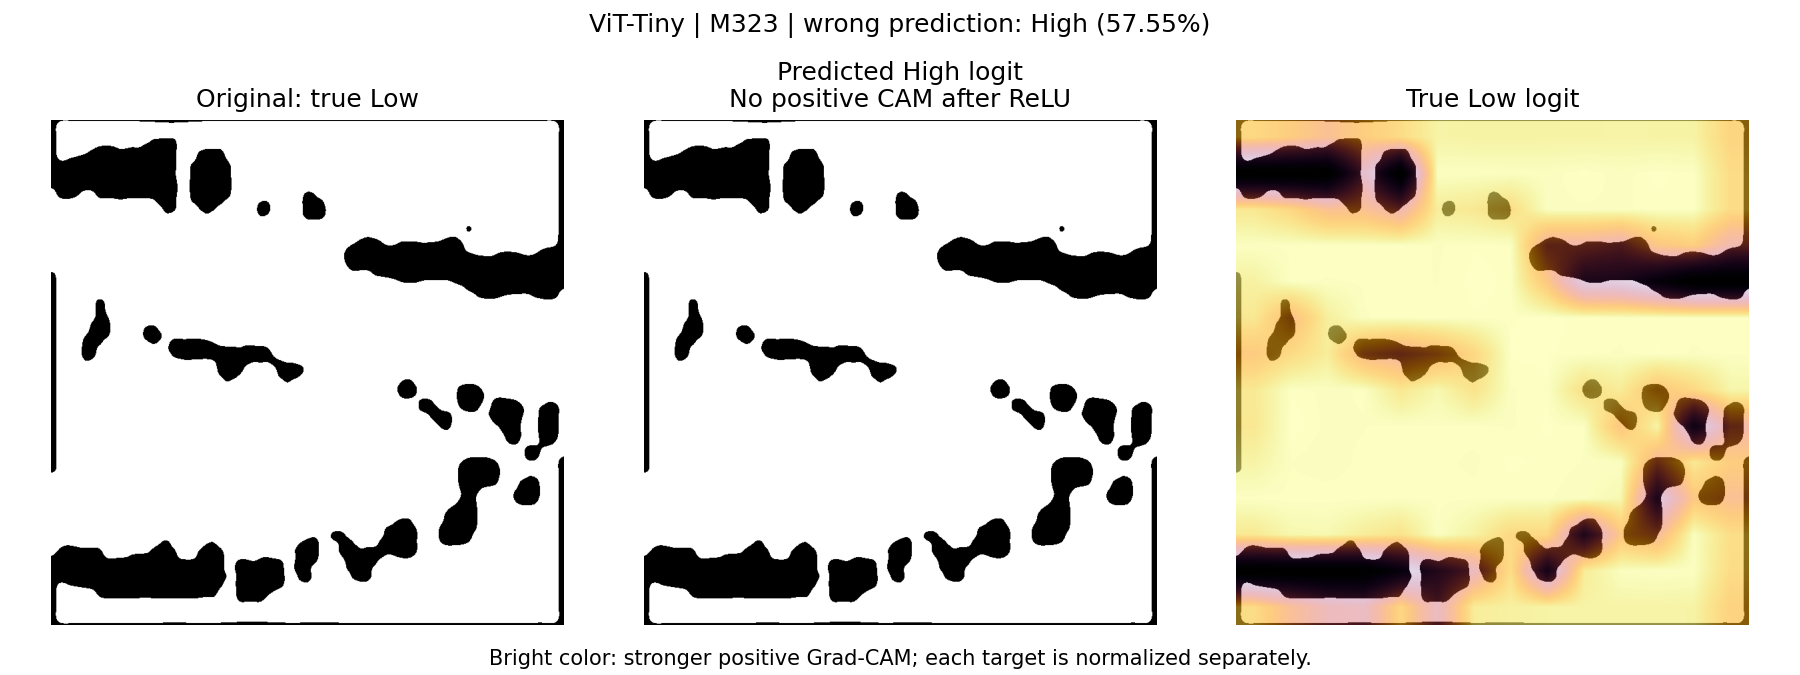

### ViT-Tiny — M93
True **Low**, predicted **High** with probability **87.75%**.

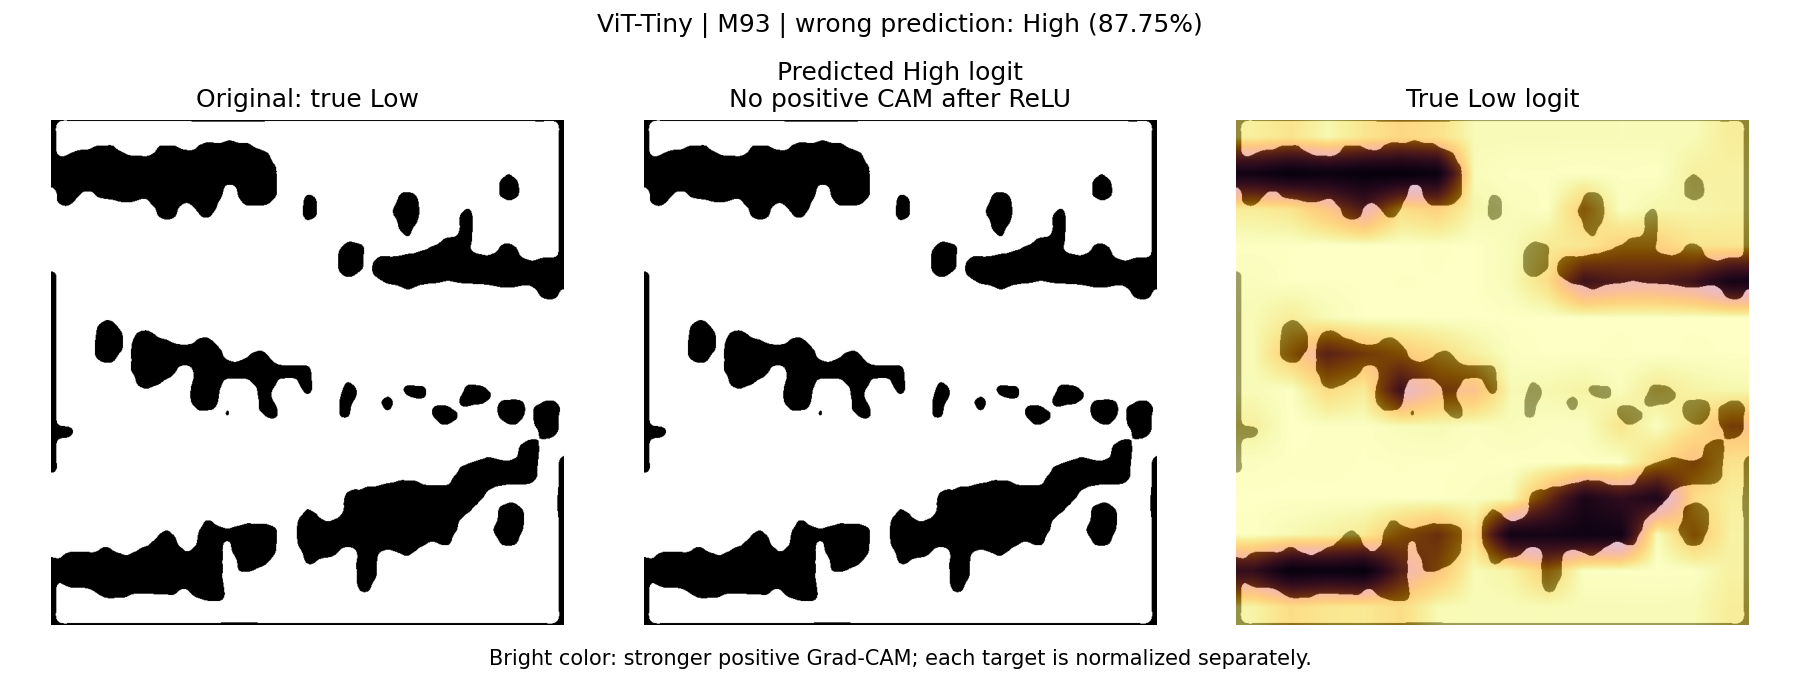

### DINOv2 — M93
True **Low**, predicted **High** with probability **94.46%**.

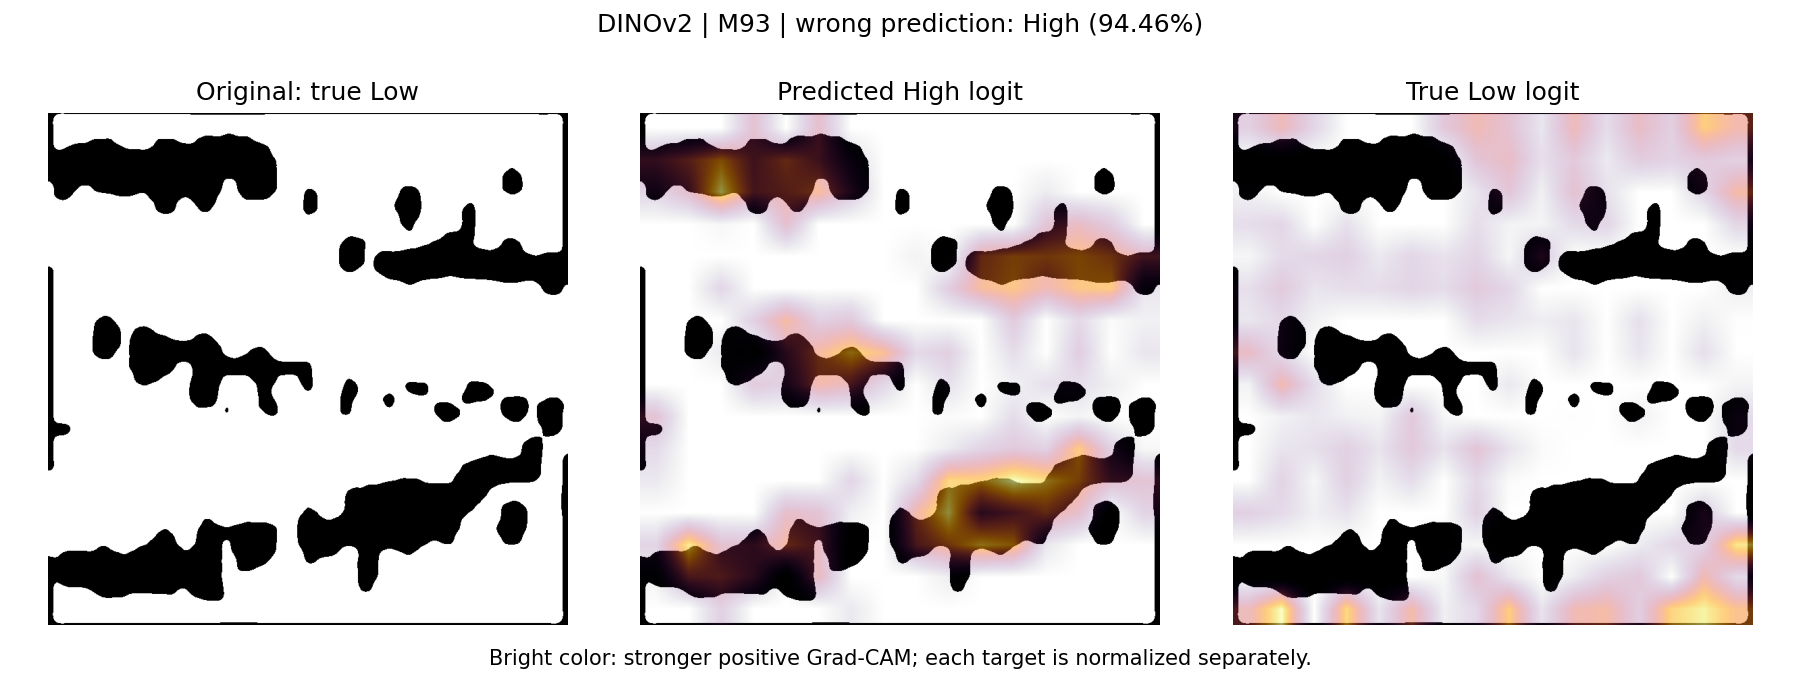

### DINOv2 — M95
True **Low**, predicted **High** with probability **55.87%**.

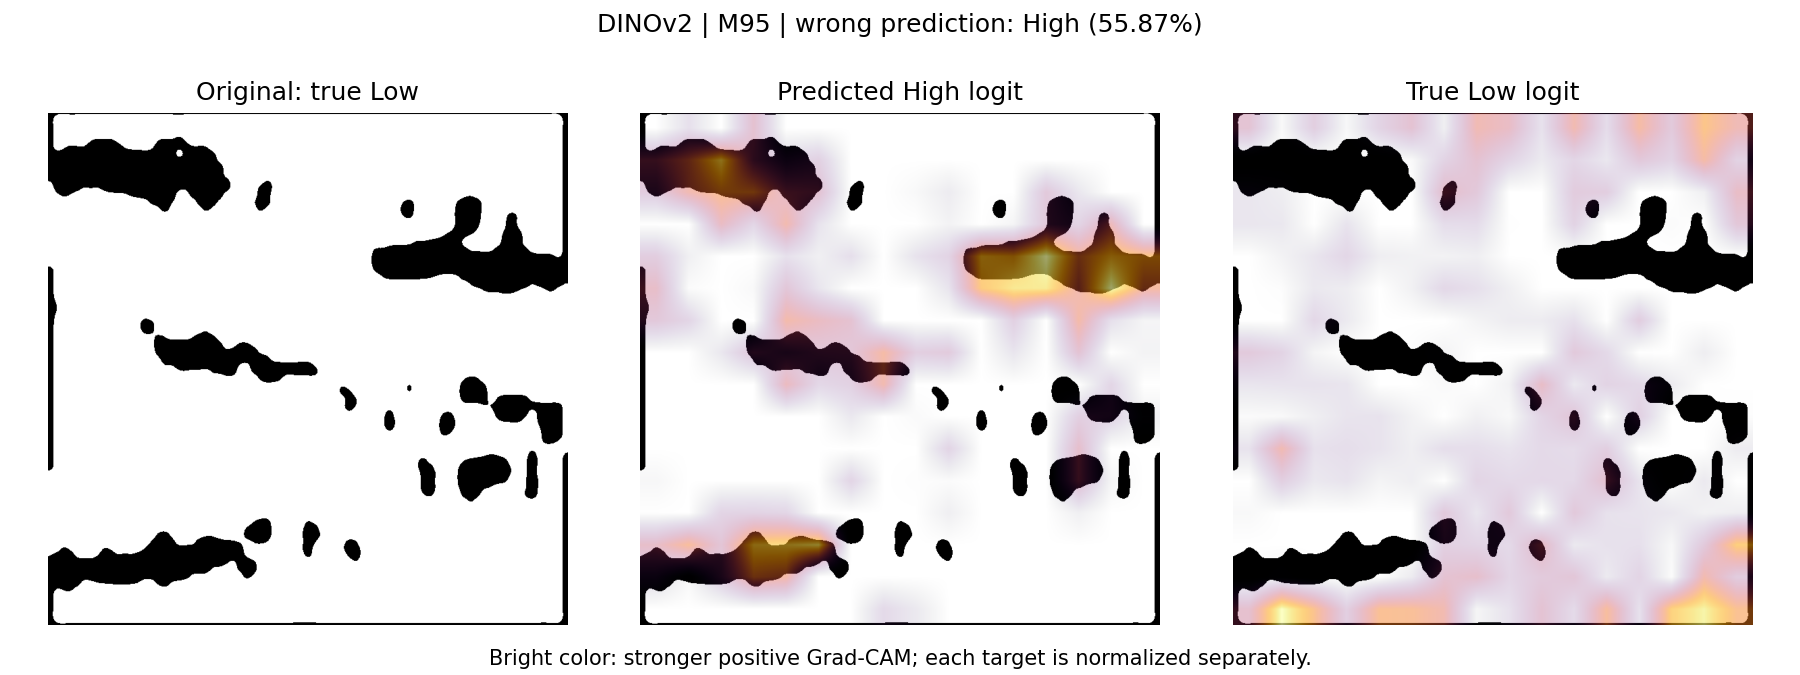

### VMamba-Tiny — M93
True **Low**, predicted **High** with probability **93.25%**.

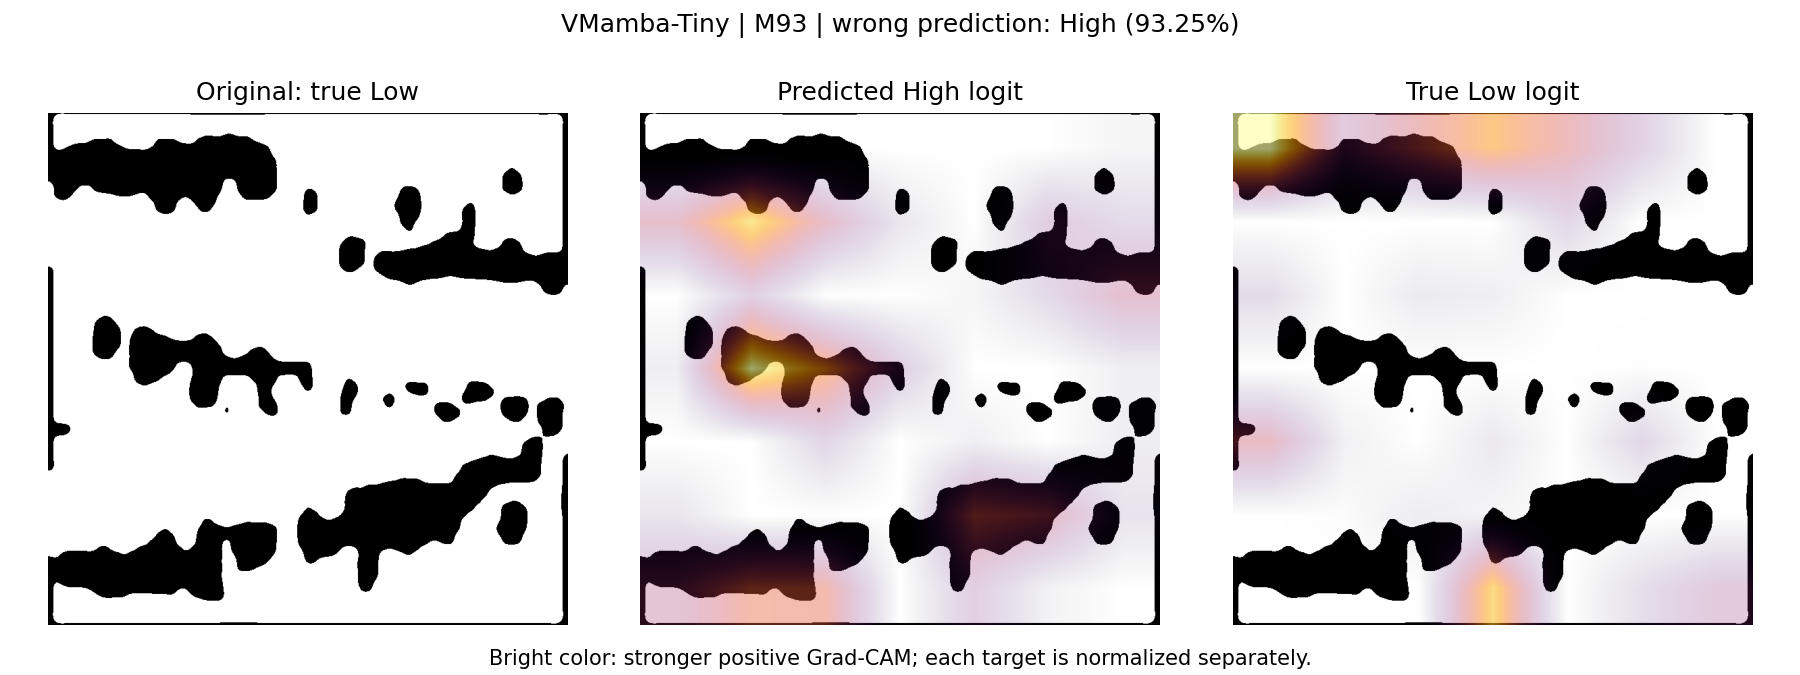

In [4]:
from IPython.display import display, Markdown, Image as NotebookImage
for status in MODEL_STATUS:
    display(Markdown(f"**{NAMES[status['model']]}:** {status['false_high_count']} true Low → predicted High; "
                     f"{status['false_low_count']} true High → predicted Low. "
                     f"All {status['audited_images']} validation predictions audited."))
    if status['false_low_count'] == 0:
        display(Markdown('No true High → predicted Low case exists for this saved checkpoint.'))
for row in SUMMARY:
    display(Markdown(f"### {NAMES[row['model']]} — {Path(row['file']).stem.split('_')[0]}\n"
                     f"True **{CLASSES[row['true_label']]}**, predicted **{CLASSES[row['predicted_label']]}** "
                     f"with probability **{row['prediction_confidence']:.2%}**."))
    display(NotebookImage(filename=str(Path(row['output_directory']) / 'comparison.png')))


## Reading the figures

- Bright regions support the selected **class logit locally** at the chosen feature layer.
- Compare locations, not absolute color strengths: Low and High maps are normalized separately.
- Softmax probability is not calibrated certainty.
- A blank positive map means this Grad-CAM target had no positive map; it is not evidence that no pixels matter.
- Spatial patterns suggest follow-up tests; they do not prove an electromagnetic mechanism or the cause of an error.
- These are validation examples used for checkpoint selection, not an independent test set. Keep this dataset separate from RDN peak-index labels.

Native maps, overlay PNGs, prediction audits, raw logits, error counts, and provenance are in `OUTPUT_DIR`.